In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# 공공데이터 스타일 데이터 생성 (따릉이 일별 대여 기록 — 가상)
np.random.seed(7)
n_days = 180
dates = pd.date_range("2025-01-01", periods=n_days, freq="D")
# 계절성: 봄·여름에 대여 증가
seasonal = 3000 + 2500 * np.sin(np.linspace(0, np.pi, n_days))
rentals = (seasonal + np.random.normal(0, 400, n_days)).round().astype(int)

bike = pd.DataFrame({
    "date": dates,
    "rentals": rentals,
    "avg_temp": (np.linspace(-2, 28, n_days) + np.random.normal(0, 2, n_days)).round(1),
    "rainfall": np.random.choice([0, 0, 0, 0, 5, 12, 30], n_days),
    "station_area": np.random.choice(["강남", "마포", "송파", "종로", " 강남 "], n_days),
})
# 오염 심기: 대여수 결측, 기온 이상치, 중복 행
bike.loc[np.random.choice(n_days, 8, replace=False), "rentals"] = np.nan
bike.loc[50, "avg_temp"] = 250.0     # 센서 오류로 보이는 이상치
bike = pd.concat([bike, bike.iloc[[3]]], ignore_index=True)  # 중복 1건

print("따릉이 데이터 준비 완료:", bike.shape)
bike.head()

따릉이 데이터 준비 완료: (181, 5)


,date,rentals,avg_temp,rainfall,station_area
0,2025-01-01,3676.0,-3.0,12,마포
1,2025-01-02,2857.0,-1.1,0,마포
2,2025-01-03,3101.0,-1.1,0,강남
3,2025-01-04,3295.0,0.9,0,강남
4,2025-01-05,2860.0,-1.1,0,마포


In [11]:
# 시나리오 1 — 구조 진단
print("shape:", bike.shape)
bike.info()
display(bike.describe())

shape: (181, 5)
<class 'pandas.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          181 non-null    datetime64[us]
 1   rentals       173 non-null    float64       
 2   avg_temp      181 non-null    float64       
 3   rainfall      181 non-null    int64         
 4   station_area  181 non-null    str           
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 8.3 KB


,date,rentals,avg_temp,rainfall
count,181,173.000000,181.000000,181.000000
mean,2025-03-31 00:31:49.392265,4531.757225,14.169061,5.298343
min,2025-01-01 00:00:00,2514.000000,-4.900000,0.000000
25%,2025-02-14 00:00:00,3841.000000,5.100000,0.000000
50%,2025-03-31 00:00:00,4708.000000,13.100000,0.000000
75%,2025-05-15 00:00:00,5243.000000,20.600000,5.000000
max,2025-06-29 00:00:00,6388.000000,250.000000,30.000000
std,NaN,889.609013,19.742786,9.687303


In [12]:
# 시나리오 1 — 구조 진단
print("shape:", bike.shape)
bike.info()
display(bike.describe())

shape: (181, 5)
<class 'pandas.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          181 non-null    datetime64[us]
 1   rentals       173 non-null    float64       
 2   avg_temp      181 non-null    float64       
 3   rainfall      181 non-null    int64         
 4   station_area  181 non-null    str           
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 8.3 KB


,date,rentals,avg_temp,rainfall
count,181,173.000000,181.000000,181.000000
mean,2025-03-31 00:31:49.392265,4531.757225,14.169061,5.298343
min,2025-01-01 00:00:00,2514.000000,-4.900000,0.000000
25%,2025-02-14 00:00:00,3841.000000,5.100000,0.000000
50%,2025-03-31 00:00:00,4708.000000,13.100000,0.000000
75%,2025-05-15 00:00:00,5243.000000,20.600000,5.000000
max,2025-06-29 00:00:00,6388.000000,250.000000,30.000000
std,NaN,889.609013,19.742786,9.687303


In [13]:
# 시나리오 2 — 품질 진단
print("[결측치]")
print(bike.isnull().sum())
print("\n중복 행:", bike.duplicated().sum())
print("\n[station_area 값의 종류]")
print(bike["station_area"].unique())
print("\n기온 이상치 확인(상위 3개):")
print(bike["avg_temp"].sort_values(ascending=False).head(3).tolist())

[결측치]
date            0
rentals         8
avg_temp        0
rainfall        0
station_area    0
dtype: int64

중복 행: 1

[station_area 값의 종류]
<ArrowStringArray>
['마포', ' 강남 ', '강남', '송파', '종로']
Length: 5, dtype: str

기온 이상치 확인(상위 3개):
[250.0, 31.8, 30.6]


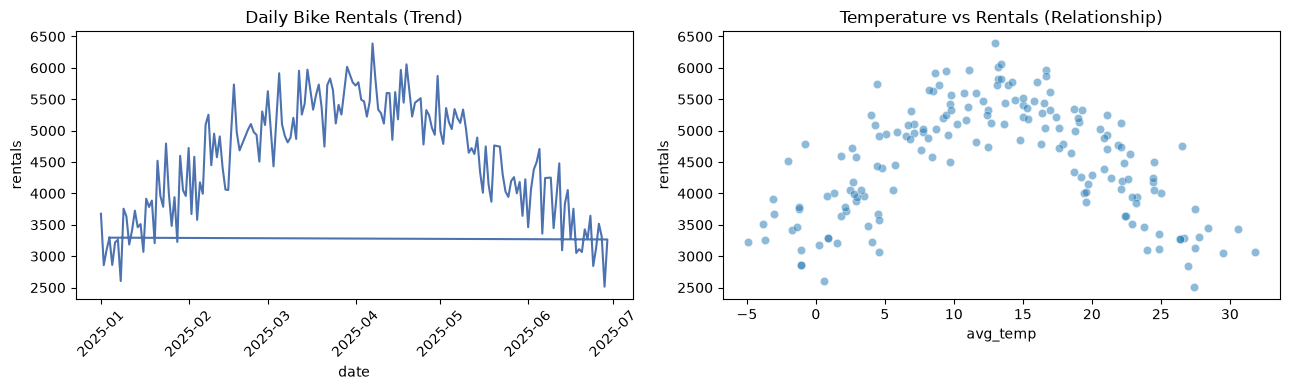

In [14]:
# 시나리오 3 — 시각화 (이상치 제거 후)
clean = bike[(bike["avg_temp"] < 60)].dropna(subset=["rentals"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# 추이
axes[0].plot(clean["date"], clean["rentals"], color="#4C72B0")
axes[0].set_title("Daily Bike Rentals (Trend)")
axes[0].set_xlabel("date"); axes[0].set_ylabel("rentals")
axes[0].tick_params(axis="x", rotation=45)
# 관계
sns.scatterplot(data=clean, x="avg_temp", y="rentals", alpha=0.5, ax=axes[1])
axes[1].set_title("Temperature vs Rentals (Relationship)")
axes[1].set_xlabel("avg_temp"); axes[1].set_ylabel("rentals")
plt.tight_layout(); plt.show()

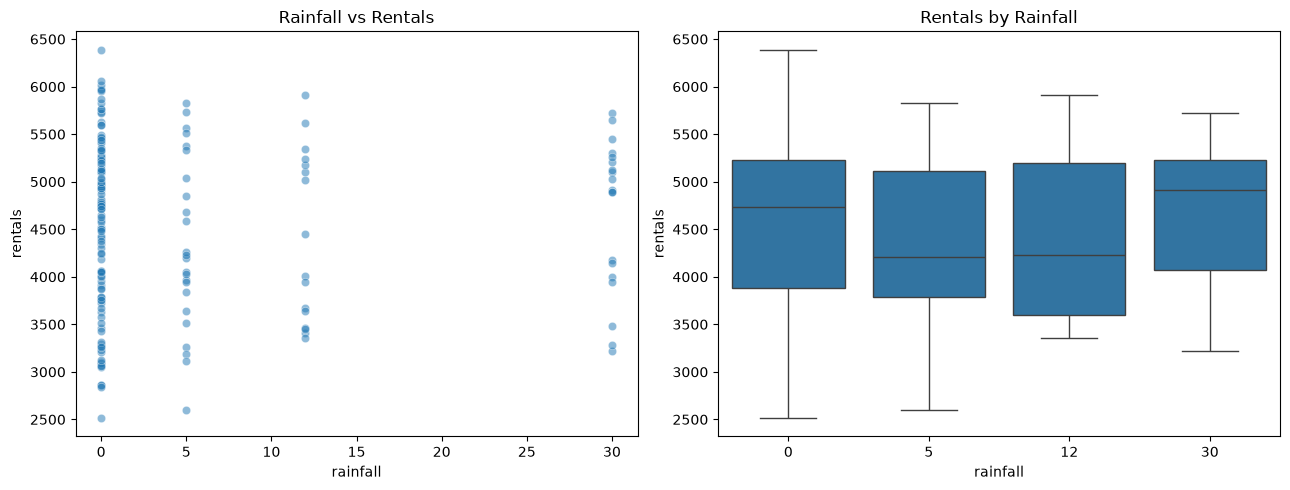

rainfall
0     4563.0
5     4347.0
12    4425.0
30    4673.0
Name: rentals, dtype: float64
상관계수: 0.03


In [17]:
# ==============================================================
# 심화 과제 1 — 강수량(rainfall)과 대여 수(rentals)의 관계
# ==============================================================

# 결측·중복·기온 이상치 제외
clean = bike.drop_duplicates()
clean = clean.dropna(subset=["rentals"])
clean = clean[clean["avg_temp"] < 45]

# 시각화
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=clean, x="rainfall", y="rentals",
                alpha=0.5, ax=axes[0])
axes[0].set_title("Rainfall vs Rentals")

sns.boxplot(data=clean, x="rainfall", y="rentals", ax=axes[1])
axes[1].set_title("Rentals by Rainfall")

plt.tight_layout()
plt.show()

# 숫자로 확인
print(clean.groupby("rainfall")["rentals"].mean().round(0))
corr = clean["rainfall"].corr(clean["rentals"])
print("상관계수:", round(corr, 2))

# 따릉이 대여 데이터 — 기초 EDA 리포트

## 1. 데이터 개요
- 행/열: (181행, 5열) — 180일치 기록에 중복 1행이 섞여 181행
- 기간: 2025-01-01 ~ 2025-06-29 (일별 기록)
- 주요 컬럼: date, rentals, avg_temp, rainfall, station_area

## 2. 구조 진단 (shape / info / describe)
- 자료형 요약: date는 datetime으로 인식됨, rentals는 결측 때문에 정수가 아닌 실수(float), avg_temp는 실수, rainfall은 정수, station_area는 문자열
- 수치 요약에서 눈에 띈 점: rentals 평균 4,531.8건 / avg_temp 최댓값 250.0℃ → 두 번째로 높은 값이 31.8℃라 센서 오류로 보이는 이상치. 이 값 때문에 기온 평균(14.2℃)과 표준편차(19.7)도 부풀려져 있음

## 3. 품질 진단 (결측 / 중복 / 표기)
- 결측: rentals 8건 (다른 컬럼은 결측 없음)
- 중복: 1건 — 2025-01-04 행이 똑같이 한 번 더 기록됨
- 표기 혼재: station_area에 '강남'(44건)과 ' 강남 '(앞뒤 공백, 34건)이 따로 집계됨 → 실제 강남은 78건이지만 쪼개져서 과소평가됨

## 4. 패턴 (시각화에서 읽은 것)
- 추이: 1월(평균 3,605건)에서 4월(5,456건)까지 증가했다가 6월(3,608건)에 다시 감소 → 봄에 정점을 찍는 산 모양의 계절성
- 관계: 기온-대여 상관계수 0.00으로 뚜렷한 직선 관계 없음 (중복·결측·이상치 제외 후). 기온은 6월까지 계속 오르는데 대여는 4월 이후 줄어들기 때문 → 기온이 너무 낮거나 너무 높으면 대여가 줄어드는 곡선 관계일 가능성

## 5. 다음 분석 제안
- 기온 250℃는 삭제하거나 앞뒤 날짜 기온으로 대체 — 값 하나가 평균과 그래프를 크게 왜곡하기 때문
- rentals 결측 8건은 특정 날짜·지역에 몰려 있는지 확인 후 처리 결정 — 결측에도 이유가 있을 수 있어서
- 중복 1건 삭제, station_area는 strip()으로 공백 제거해 '강남'으로 통일 — 같은 지역이 둘로 나뉘면 지역별 비교가 틀어지기 때문
- 기온 구간별 평균 대여 수를 그려 곡선 관계인지 확인하고, 강수량(현재 상관계수 0.03)·요일의 영향도 추가로 보고 싶음 — 기온 하나로는 대여 변화가 설명되지 않았기 때문